# Expectation-Maximization and Gaussian Mixture Models

Explore clustering geometry, sensitivity to initialization, likelihood singularities, covariance constraints, generative sampling and Bayesian mixture weights.

## Clustering geometry

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

### Synthetic isotropic clusters

Generate 1,500 observations in three clusters with standard deviation 1 and seed 170.

In [2]:
X, y_true = make_blobs(
    n_samples=1500,
    centers=3,
    cluster_std=1.0,
    random_state=170
)

### Anisotropic transformation

Apply a fixed linear transformation to stretch and rotate the cluster geometry.

In [3]:
transformation = np.array([[0.6, -0.6],
                           [-0.4, 0.8]])
X_aniso = X @ transformation

### K-Means

Fit three centers by minimizing within-cluster squared Euclidean distances. The nearest-center decision regions are Voronoi cells.

In [4]:
kmeans = KMeans(n_clusters=3, random_state=170, n_init="auto")
labels_km = kmeans.fit_predict(X_aniso)
centers_km = kmeans.cluster_centers_

### Full-covariance Gaussian mixture

Fit three Gaussian components, each with its own covariance, allowing rotated and elongated density contours.

In [5]:
gmm = GaussianMixture(n_components=3, covariance_type="full", random_state=170)
labels_gmm = gmm.fit_predict(X_aniso)

### Visual comparison

Compare cluster assignments and estimated centers or means. Report the fitted mixture weights and average log-likelihood lower bound; the latter is not a K-Means objective.

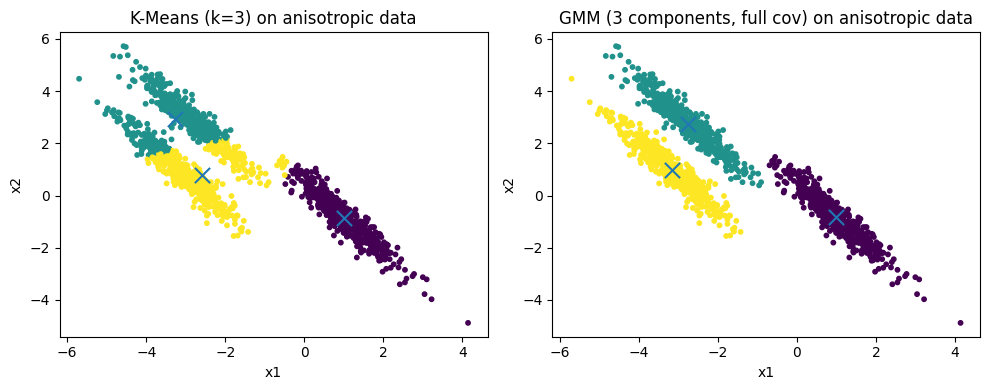

Saved figure: q6_part1_kmeans_vs_gmm.png

[Part 1 Numerical Summary]
GMM lower_bound_ (avg log-likelihood per sample): -2.4606772354960076
GMM weights: [0.33322706 0.33342641 0.33334653]
KMeans centers:
 [[ 1.0128483  -0.85916914]
 [-3.28144158  2.91912555]
 [-2.58926381  0.79458914]]
GMM means:
 [[ 0.98487467 -0.82222179]
 [-2.74375393  2.75538735]
 [-3.17230061  0.97982079]]


In [6]:
gmm_ll = gmm.lower_bound_     # log-likelihood
gmm_weights = gmm.weights_
gmm_means = gmm.means_

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.scatter(X_aniso[:, 0], X_aniso[:, 1], c=labels_km, s=10)
plt.scatter(centers_km[:, 0], centers_km[:, 1], marker="x", s=120)
plt.title("K-Means (k=3) on anisotropic data")
plt.xlabel("x1"); plt.ylabel("x2")

plt.subplot(1, 2, 2)
plt.scatter(X_aniso[:, 0], X_aniso[:, 1], c=labels_gmm, s=10)
plt.scatter(gmm_means[:, 0], gmm_means[:, 1], marker="x", s=120)
plt.title("GMM (3 components, full cov) on anisotropic data")
plt.xlabel("x1"); plt.ylabel("x2")

plt.tight_layout()
out_path = "q6_part1_kmeans_vs_gmm.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved figure:", out_path)

print("\n[Part 1 Numerical Summary]")
print("GMM lower_bound_ (avg log-likelihood per sample):", gmm_ll)
print("GMM weights:", gmm_weights)
print("KMeans centers:\n", centers_km)
print("GMM means:\n", gmm_means)

### Geometry interpretation
K-Means minimizes squared Euclidean distance, so it cannot adapt its distance geometry to each cluster's covariance. Full-covariance GMMs instead use covariance-adjusted distances, log determinants and mixing weights. The fitted GMM has nearly equal weights (0.33323, 0.33343, 0.33335) and an average log-likelihood lower bound of -2.460677. The comparison is qualitative rather than an external clustering-accuracy benchmark.

## Nonconvex optimization and initialization

### Overlapping synthetic clusters

Generate 500 observations with four centers and standard deviation 2.5.

In [7]:
X_hard, y_hard = make_blobs(
    n_samples=500,
    centers=4,
    cluster_std=2.5,
    random_state=42
)

### Fifty random initializations

Fit four-component GMMs with one random initialization per model and seeds 0–49. Store convergence, iteration counts and final lower bounds.

In [8]:
final_ll = []
n_iters = []
converged = []

for i in range(50):
    gmm = GaussianMixture(
        n_components=4,
        init_params="random",
        n_init=1,
        covariance_type="full",
        random_state=i
    )
    gmm.fit(X_hard)
    final_ll.append(gmm.lower_bound_)
    n_iters.append(gmm.n_iter_)
    converged.append(gmm.converged_)

final_ll = np.array(final_ll)
n_iters = np.array(n_iters)
converged = np.array(converged)


### Distribution of final likelihoods

The histogram reveals different attainable objective values, illustrating the sensitivity of EM to its starting point.

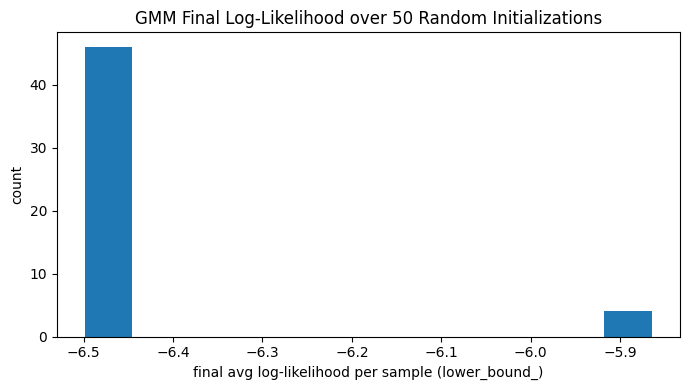

Saved figure: q6_part2_ll_hist.png

[Part 2 Numerical Summary]
Converged runs: 50 / 50
LL: min = -6.498143590493189 | median = -6.497577681353046 | mean = -6.447312217555111 | max = -5.86474815415633
LL std = 0.17031840860239167
Iterations: min = 2 | median = 2.0 | mean = 4.94 | max = 42


In [9]:
plt.figure(figsize=(7,4))
plt.hist(final_ll, bins=12)
plt.title("GMM Final Log-Likelihood over 50 Random Initializations")
plt.xlabel("final avg log-likelihood per sample (lower_bound_)")
plt.ylabel("count")
plt.tight_layout()

out_path = "q6_part2_ll_hist.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved figure:", out_path)

# results
print("\n[Part 2 Numerical Summary]")
print("Converged runs:", converged.sum(), "/ 50")
print("LL: min =", final_ll.min(), "| median =", np.median(final_ll), "| mean =", final_ll.mean(), "| max =", final_ll.max())
print("LL std =", final_ll.std())
print("Iterations: min =", n_iters.min(), "| median =", np.median(n_iters), "| mean =", n_iters.mean(), "| max =", n_iters.max())


### Initialization results
All 50 models converged by the algorithm's stopping rule, but final lower bounds ranged from -6.498144 to -5.864748 (median -6.497578, mean -6.447312, SD 0.170318). Iterations ranged from 2 to 42. Convergence does not guarantee the global optimum. Multiple initializations and selection by the highest attained objective provide a practical mitigation.

## Likelihood singularity and covariance regularization

### Construct an outlier scenario

Append [10, 10] to the first 100 original synthetic observations.

[Part 3] Dataset shape: (101, 2)
[Part 3] Last point (outlier): [10. 10.]


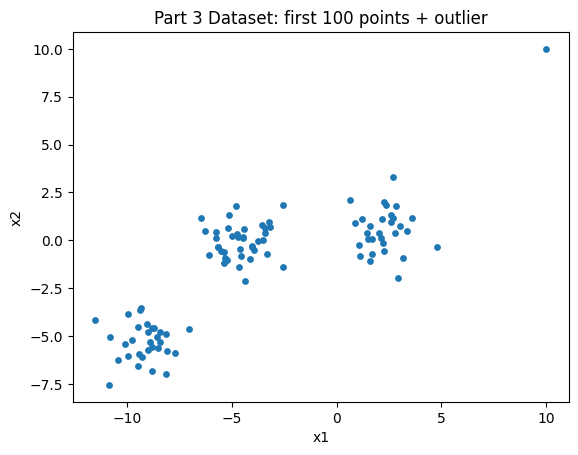

In [10]:
X_part3 = np.vstack([X[:100], np.array([[10.0, 10.0]])])

print("[Part 3] Dataset shape:", X_part3.shape)
print("[Part 3] Last point (outlier):", X_part3[-1])

#  visualize
plt.figure()
plt.scatter(X_part3[:,0], X_part3[:,1], s=15)
plt.title("Part 3 Dataset: first 100 points + outlier")
plt.xlabel("x1"); plt.ylabel("x2")
plt.show()

### Unregularized mixture

Set covariance regularization to zero and fit a two-component full-covariance mixture.

In [11]:
gmm_sing = GaussianMixture(
    n_components=2,
    covariance_type="full",
    reg_covar=0.0,           #  no regularization
    init_params="random",
    n_init=1,
    random_state=42
)

### Deliberate initialization

Place one starting mean at the first observation and another at [15, 15].

In [12]:
gmm_sing.means_init = np.array([X_part3[0], [15.0, 15.0]], dtype=float)

print("Forced means_init:\n", gmm_sing.means_init)


Forced means_init:
 [[-5.19811282  0.64186932]
 [15.         15.        ]]


### Detect covariance collapse

Catch the fitting exception caused by an ill-defined empirical covariance. A Gaussian component collapsing around a point can make the likelihood unbounded as its determinant approaches zero.

In [13]:
try:
    gmm_sing.fit(X_part3)
    print(" Fit completed WITHOUT error (unexpected).")
    print(" Final lower_bound_:", gmm_sing.lower_bound_)
    print(" Final means:\n", gmm_sing.means_)
    print(" Final covariances:\n", gmm_sing.covariances_)
except Exception as e:
    print(" Caught error as expected:")
    print(type(e).__name__, ":", e)

[Part 3] Caught error as expected:
ValueError : Fitting the mixture model failed because some components have ill-defined empirical covariance (for instance caused by singleton or collapsed samples). Try to decrease the number of components, or increase reg_covar.


### Regularized mixture

Add $10^{-6}$ to the covariance diagonal through `reg_covar`. This prevents zero eigenvalues in the empirical covariance update and permits the fit to complete.

In [14]:
gmm_reg = GaussianMixture(
    n_components=2,
    covariance_type="full",
    reg_covar=1e-6,      # small regularization
    init_params="random",
    n_init=1,
    random_state=42
)
gmm_reg.means_init = np.array([X_part3[0], [15.0, 15.0]], dtype=float)

gmm_reg.fit(X_part3)
print("[Part 3 - reg] Fit completed.")
print("[Part 3 - reg] lower_bound_:", gmm_reg.lower_bound_)
print("[Part 3 - reg] means:\n", gmm_reg.means_)

[Part 3 - reg] Fit completed.
[Part 3 - reg] lower_bound_: -4.8138953109439635
[Part 3 - reg] means:
 [[-3.95210977 -1.5092152 ]
 [10.         10.        ]]


### Singularity results
The unregularized fit raises a covariance-related `ValueError`. With diagonal regularization the model fits, yielding a lower bound of -4.813895 and one mean at the outlier [10, 10]. For $x=\mu$, the Gaussian density is proportional to $|\Sigma|^{-1/2}$, which diverges as a covariance collapses. Regularization prevents this degeneracy, but does not prove the outlier is a meaningful cluster.

## Covariance constraints and model flexibility

### Fit four covariance structures

Compare spherical (one variance per component), diagonal (axis-aligned), tied (shared full covariance) and full (component-specific unrestricted covariance).

In [16]:
cov_types = ["spherical", "diag", "tied", "full"]
gmms = {}
labels_dict = {}

for cov in cov_types:
    gmm = GaussianMixture(
        n_components=3,
        covariance_type=cov,
        random_state=170
    )
    gmm.fit(X_aniso)
    labels = gmm.predict(X_aniso)

    gmms[cov] = gmm
    labels_dict[cov] = labels

print("Models fitted successfully.")

Models fitted successfully.


### Covariance ellipses

Use singular-value decomposition to obtain principal axes and orientations for the displayed ellipses.

In [19]:
def draw_ellipse(position, covariance, ax, **kwargs):
    if covariance.shape == (2, 2):
        U, s, Vt = np.linalg.svd(covariance)
        angle = np.degrees(np.arctan2(U[1, 0], U[0, 0]))
        width, height = 2 * np.sqrt(s)
    else:
        angle = 0
        width, height = 2 * np.sqrt(covariance)

    ell = Ellipse(
        xy=position,
        width=width,
        height=height,
        angle=angle,
        **kwargs
    )
    ax.add_patch(ell)


### Compare fitted geometries

Full covariance is most flexible; simpler constraints reduce the number of parameters and can be more stable with limited data.

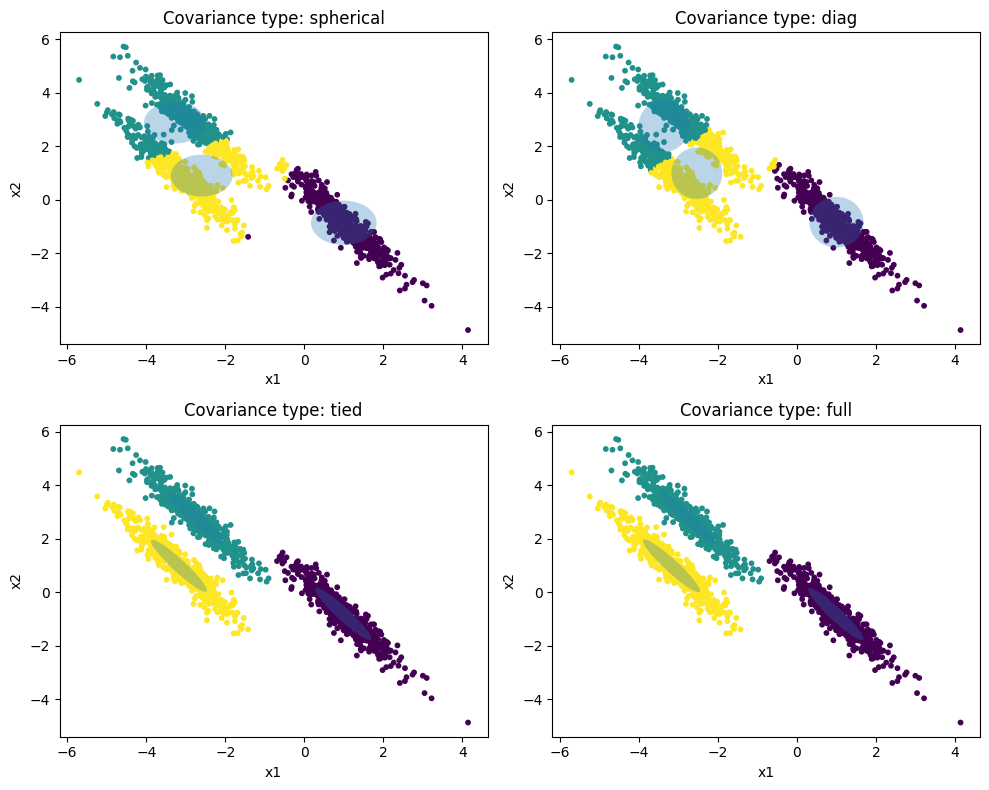

Saved figure: q6_part4_covariance_types.png


In [20]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

for ax, cov in zip(axes, cov_types):
    gmm = gmms[cov]
    labels = labels_dict[cov]

    ax.scatter(X_aniso[:, 0], X_aniso[:, 1], c=labels, s=10, cmap="viridis")

    for k in range(3):
        if cov == "tied":
            cov_matrix = gmm.covariances_
        elif cov == "spherical":
            cov_matrix = np.eye(2) * gmm.covariances_[k]
        elif cov == "diag":
            cov_matrix = np.diag(gmm.covariances_[k])
        else:  # full
            cov_matrix = gmm.covariances_[k]

        draw_ellipse(gmm.means_[k], cov_matrix, ax, alpha=0.3)

    ax.set_title(f"Covariance type: {cov}")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")

plt.tight_layout()
plt.savefig("q6_part4_covariance_types.png", dpi=300)
plt.show()

print("Saved figure: q6_part4_covariance_types.png")

### Covariance interpretation
Spherical components use circles, diagonal components allow axis-aligned ellipses, tied covariance imposes a common shape, and full covariance allows each component its own orientation and shape. Greater flexibility can reduce approximation bias but increases estimation variance and cost. The figure illustrates geometry; no held-out criterion establishes which covariance type is universally preferable.

## Generative modeling of handwritten digits

### Load digit images

Use scikit-learn Digits: 1,797 observations with 64 features representing 8 × 8 images.

In [22]:
from sklearn.datasets import load_digits
np.random.seed(42)
digits = load_digits()
X_digits = digits.data   # (n_samples, 64)
y_digits = digits.target

print("Dataset shape:", X_digits.shape)
print("Number of classes:", len(np.unique(y_digits)))

Dataset shape: (1797, 64)
Number of classes: 10


### Fit a density model

Fit a 30-component full-covariance Gaussian mixture to flattened pixel vectors without using class labels.

In [23]:
gmm_digits = GaussianMixture(
    n_components=30,
    covariance_type='full',
    random_state=42
)

gmm_digits.fit(X_digits)

print("GMM trained successfully.")
print("Final average log-likelihood per sample:", gmm_digits.lower_bound_)

GMM trained successfully.
Final average log-likelihood per sample: 36.711061367690114


### Sample from the fitted mixture

Generate ten new 64-dimensional observations and record their latent component indices.

In [24]:
X_new, component_ids = gmm_digits.sample(10)

print("Generated samples shape:", X_new.shape)
print("Sampled component IDs:", component_ids)

Generated samples shape: (10, 64)
Sampled component IDs: [ 1  7  7 11 11 12 20 25 27 29]


### Visualize generated samples

Reshape the sampled vectors to 8 × 8 images. Samples are qualitative illustrations; Gaussian draws are not constrained to valid pixel ranges.

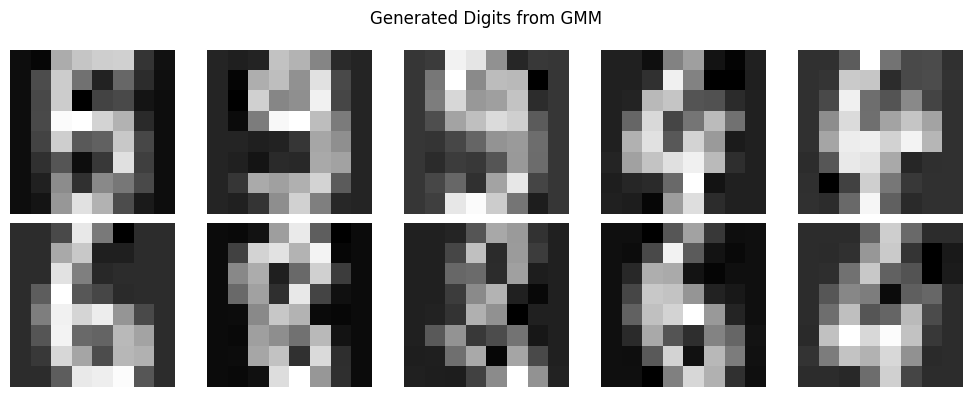

In [25]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.flat):
    ax.imshow(X_new[i].reshape(8, 8), cmap='gray')
    ax.axis('off')

plt.suptitle("Generated Digits from GMM")
plt.tight_layout()
plt.show()

### Generative interpretation
The fitted digit mixture has an average training log-likelihood lower bound of 36.711061 and produces ten samples of shape (10, 64). GMM learns a density $p(x)$ from which new observations can be sampled, whereas discriminative classifiers such as logistic regression learn $p(y\mid x)$. Standard K-Means provides centroids but no within-cluster probability distribution for new variations. The sample images are qualitative, not a validated generative-quality metric.

## Bayesian Gaussian mixture and sparse weights

In [26]:
from sklearn.mixture import BayesianGaussianMixture

### Generate three-cluster data

Generate 500 samples with three centers and seed 42.

In [27]:
X, y = make_blobs(n_samples=500, centers=3, random_state=42)

### Bayesian mixture fitting

Allow ten components and use a small concentration prior of $10^{-3}$. Scikit-learn defaults to a truncated Dirichlet-process prior, rather than a finite symmetric Dirichlet unless explicitly specified.

In [ ]:
bgmm = BayesianGaussianMixture(
    n_components=10,
    weight_concentration_prior=1e-3,  # alpha = 1e-3
    covariance_type='full',
    random_state=42
)
bgmm.fit(X)

### Inspect active components

Count learned component weights greater than 0.01 as a descriptive threshold for active components.

In [32]:
weights = bgmm.weights_

print("Learned mixture weights:")
print(weights)

print("\nNumber of components with weight > 0.01:")
print(np.sum(weights > 0.01))


Learned mixture weights:
[2.01388564e-03 2.00982887e-03 3.33950041e-01 1.99972007e-03
 3.29993146e-01 1.98170384e-03 1.96980149e-03 1.95797068e-03
 3.24121974e-01 1.92759500e-06]

Number of components with weight > 0.01:
3


### Visualize mixture weights

Plot the ten fitted weights to examine how probability mass concentrates on a small number of components.

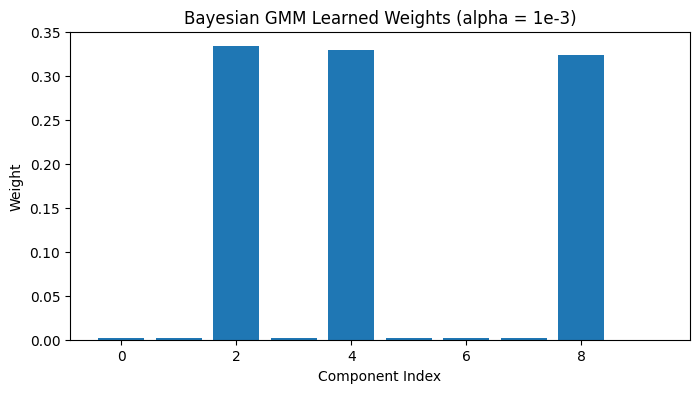

In [33]:
plt.figure(figsize=(8,4))
plt.bar(range(len(weights)), weights)
plt.xlabel("Component Index")
plt.ylabel("Weight")
plt.title("Bayesian GMM Learned Weights (alpha = 1e-3)")
plt.show()

### Bayesian mixture results and conclusions
Three of ten components exceed weight 0.01, with weights approximately 0.33395, 0.32999 and 0.32412. Most remaining weights are near 0.002 or lower. A small concentration parameter favors sparse effective mixture weights; the observed three active components align with the synthetic three-center construction. The threshold is descriptive, and the prior does not guarantee automatic recovery of the true cluster count on arbitrary data. See [analysis notes](docs/gaussian_mixture_models.md).